# 🎨 vs 🕵️ — A GAN that learns to draw handwritten digits
**Deep Learning · Group A implementation · Generative Adversarial Network (DCGAN-style) in PyTorch**

Two neural networks play a game:
- **Generator (the Artist)** turns random noise into a fake digit image.
- **Discriminator (the Detective)** looks at an image and says how likely it is to be *real*.

They train against each other until the Artist's fakes look real.

**How to run:** open in Google Colab → `Runtime → Change runtime type → GPU` → `Runtime → Run all`.
20 epochs take about 3–5 minutes on a Colab GPU (much longer on a CPU — lower `EPOCHS` if you have no GPU).

*The outputs saved in this notebook come from a full 20-epoch test run of this exact code on a CPU. Run it again on Colab to reproduce them; numbers will differ slightly.*


## 1. Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)                      # same random numbers every run -> repeatable results
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)

Z_DIM      = 100    # size of the random noise vector the Artist starts from
BATCH_SIZE = 128
EPOCHS     = 20
LR         = 2e-4   # learning rate recommended in the DCGAN paper
BETA1      = 0.5    # Adam momentum term recommended in the DCGAN paper

Running on: cpu


## 2. Dataset & preprocessing
**MNIST**: 60,000 grayscale images of handwritten digits, each 28 × 28 pixels.

Preprocessing:
1. `ToTensor()` → pixel values go from 0–255 to **0–1**
2. `Normalize(0.5, 0.5)` → values go from 0–1 to **−1 to +1** (matches the Generator's `Tanh` output range)

We do **not** use the labels — a GAN learns from the images alone.

Training images: 60000 | batches per epoch: 468


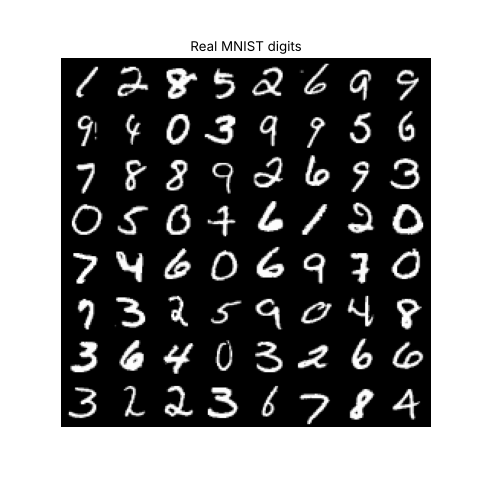

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),                  # [0, 255] -> [0, 1]
    transforms.Normalize((0.5,), (0.5,)),   # [0, 1]   -> [-1, 1]
])

train_set = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
print("Training images:", len(train_set), "| batches per epoch:", len(loader))

real_batch, _ = next(iter(loader))
plt.figure(figsize=(6, 6)); plt.axis("off"); plt.title("Real MNIST digits")
plt.imshow(vutils.make_grid(real_batch[:64], nrow=8, normalize=True).permute(1, 2, 0))
plt.show()

## 3. The Generator (the Artist 🎨)
Noise `z` (100 numbers) → **Linear** → reshape to `128 × 7 × 7` → **ConvTranspose** (upsample) → `64 × 14 × 14` → **ConvTranspose** → `1 × 28 × 28` image.

`ReLU` inside, `Tanh` at the end so pixels land in −1…+1.

In [3]:
class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.project = nn.Sequential(                     # 100 -> 128*7*7
            nn.Linear(z_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.ReLU(True),
        )
        self.up1 = nn.Sequential(                          # 128x7x7 -> 64x14x14
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
        )
        self.up2 = nn.Sequential(                          # 64x14x14 -> 1x28x28
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, z):
        x = self.project(z).view(-1, 128, 7, 7)
        x = self.up1(x)
        return self.up2(x)

## 4. The Discriminator (the Detective 🕵️)
Image `1 × 28 × 28` → **Conv** (downsample) → `64 × 14 × 14` → **Conv** → `128 × 7 × 7` → **Flatten** → **Linear** → **Sigmoid** → one number between 0 (fake) and 1 (real).

`LeakyReLU(0.2)` lets a little signal through for negative values, which keeps gradients flowing back to the Generator.

In [4]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.down1 = nn.Sequential(                        # 1x28x28 -> 64x14x14
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.down2 = nn.Sequential(                        # 64x14x14 -> 128x7x7
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.judge = nn.Sequential(                        # 128*7*7 -> 1 probability
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.judge(self.down2(self.down1(x)))

def init_weights(m):                                       # DCGAN paper: start weights from N(0, 0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

G = Generator().to(device);     G.apply(init_weights)
D = Discriminator().to(device); D.apply(init_weights)
count = lambda net: sum(p.numel() for p in net.parameters())
print(f"Generator parameters:     {count(G):,}")
print(f"Discriminator parameters: {count(D):,}")

Generator parameters:     778,305
Discriminator parameters: 138,817


## 5. Loss & optimisers
**Binary Cross-Entropy (BCE)** — the standard real-vs-fake loss.
- Detective's goal: say **1** for real images and **0** for fakes.
- Artist's goal: make the Detective say **1** for its fakes.

Each network gets its own **Adam** optimiser.

In [5]:
criterion = nn.BCELoss()
opt_D = optim.Adam(D.parameters(), lr=LR, betas=(BETA1, 0.999))
opt_G = optim.Adam(G.parameters(), lr=LR, betas=(BETA1, 0.999))

fixed_noise = torch.randn(64, Z_DIM, device=device)   # the same 64 noise vectors every epoch -> watch them improve

## 6. Training loop — the two-step dance
For every batch:
1. **Train the Detective** (Artist frozen): show real images (label 1) and fakes (label 0), update D.
2. **Train the Artist** (Detective frozen): make new fakes, ask D to judge them, but compute the loss as if the label were 1 ("real"), update G.

We track four numbers:
- `loss_D`, `loss_G` — the two losses
- `D(x)` — average score D gives **real** images (starts near 1)
- `D(G(z))` — average score D gives **fakes** (rises as the Artist improves)

In [6]:
history = {"loss_D": [], "loss_G": [], "D_x": [], "D_G_z": []}
snapshots = []                                         # one image grid per epoch

for epoch in range(1, EPOCHS + 1):
    for real, _ in loader:
        real = real.to(device)
        b = real.size(0)
        ones  = torch.ones(b, 1, device=device)        # label "real"
        zeros = torch.zeros(b, 1, device=device)       # label "fake"

        # ---- Step 1: train the Detective (D) ----
        z = torch.randn(b, Z_DIM, device=device)
        fake = G(z)
        out_real = D(real)
        out_fake = D(fake.detach())                    # .detach() = Artist is frozen in this step
        loss_D = criterion(out_real, ones) + criterion(out_fake, zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        # ---- Step 2: train the Artist (G) ----
        out = D(fake)                                  # D's weights are not updated here (only opt_G steps)
        loss_G = criterion(out, ones)                  # Artist wants D to say "real" (1)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

        history["loss_D"].append(loss_D.item()); history["loss_G"].append(loss_G.item())
        history["D_x"].append(out_real.mean().item()); history["D_G_z"].append(out_fake.mean().item())

    with torch.no_grad():
        G.eval(); snap = G(fixed_noise).cpu(); G.train()
    snapshots.append(snap)
    n = len(loader)
    print(f"Epoch {epoch:2d}/{EPOCHS} | loss_D {np.mean(history['loss_D'][-n:]):.3f} "
          f"| loss_G {np.mean(history['loss_G'][-n:]):.3f} "
          f"| D(x) {np.mean(history['D_x'][-n:]):.2f} | D(G(z)) {np.mean(history['D_G_z'][-n:]):.2f}")

Epoch  1/20 | loss_D 0.530 | loss_G 2.545 | D(x) 0.81 | D(G(z)) 0.19
Epoch  2/20 | loss_D 0.819 | loss_G 1.406 | D(x) 0.69 | D(G(z)) 0.31
Epoch  3/20 | loss_D 0.820 | loss_G 1.427 | D(x) 0.70 | D(G(z)) 0.30
Epoch  4/20 | loss_D 0.843 | loss_G 1.386 | D(x) 0.69 | D(G(z)) 0.31
Epoch  5/20 | loss_D 0.815 | loss_G 1.422 | D(x) 0.70 | D(G(z)) 0.30
Epoch  6/20 | loss_D 0.817 | loss_G 1.448 | D(x) 0.70 | D(G(z)) 0.30
Epoch  7/20 | loss_D 0.831 | loss_G 1.458 | D(x) 0.70 | D(G(z)) 0.30
Epoch  8/20 | loss_D 0.809 | loss_G 1.496 | D(x) 0.70 | D(G(z)) 0.30
Epoch  9/20 | loss_D 0.830 | loss_G 1.491 | D(x) 0.70 | D(G(z)) 0.30
Epoch 10/20 | loss_D 0.809 | loss_G 1.524 | D(x) 0.71 | D(G(z)) 0.29
Epoch 11/20 | loss_D 0.816 | loss_G 1.546 | D(x) 0.71 | D(G(z)) 0.29
Epoch 12/20 | loss_D 0.798 | loss_G 1.575 | D(x) 0.71 | D(G(z)) 0.29
Epoch 13/20 | loss_D 0.816 | loss_G 1.588 | D(x) 0.71 | D(G(z)) 0.29
Epoch 14/20 | loss_D 0.790 | loss_G 1.575 | D(x) 0.71 | D(G(z)) 0.29
Epoch 15/20 | loss_D 0.797 | loss_

## 7. Results — losses and scores

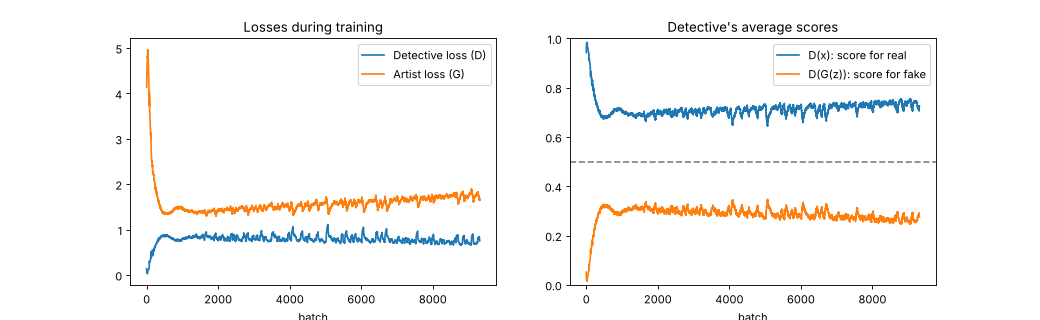

In [7]:
def smooth(v, k=50):
    return np.convolve(v, np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(smooth(history["loss_D"]), label="Detective loss (D)")
ax[0].plot(smooth(history["loss_G"]), label="Artist loss (G)")
ax[0].set_title("Losses during training"); ax[0].set_xlabel("batch"); ax[0].legend()
ax[1].plot(smooth(history["D_x"]), label="D(x): score for real")
ax[1].plot(smooth(history["D_G_z"]), label="D(G(z)): score for fake")
ax[1].axhline(0.5, ls="--", c="gray"); ax[1].set_ylim(0, 1)
ax[1].set_title("Detective's average scores"); ax[1].set_xlabel("batch"); ax[1].legend()
plt.show()

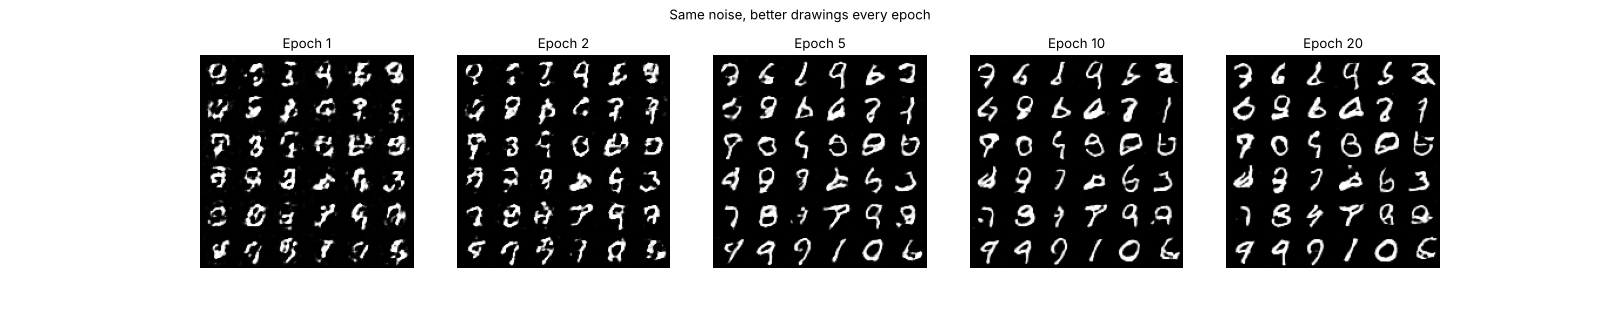

In [8]:
show = [e for e in (1, 2, 5, 10, EPOCHS) if e <= EPOCHS]
fig, ax = plt.subplots(1, len(show), figsize=(4 * len(show), 4))
for a, e in zip(np.atleast_1d(ax), show):
    a.imshow(vutils.make_grid(snapshots[e - 1][:36], nrow=6, normalize=True).permute(1, 2, 0))
    a.set_title(f"Epoch {e}"); a.axis("off")
plt.suptitle("Same noise, better drawings every epoch"); plt.show()

## 8. Evaluation — ask a digit classifier to grade the fakes
GANs have no "accuracy". A common trick (the idea behind the *Inception Score*) is to use a separately trained classifier:
- **Confidence**: is each fake clearly *one* digit? (high = sharp, readable digits)
- **Coverage**: do all 10 digits appear? (missing digits = *mode collapse*)
- **Digit Score** = Inception-Score formula with an MNIST classifier. Best possible is **10**.

We train a small CNN classifier for 1 epoch, check it on the real test set, then grade 1,000 fakes.

Classifier accuracy on real test digits: 98.0%
Digit Score  — real: 9.00 | fake: 6.47   (max 10)
Confidence   — real: 96.8% | fake: 85.8%


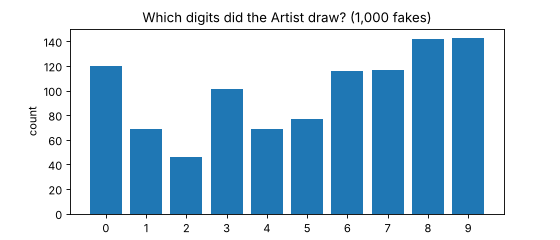

In [9]:
classifier = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
).to(device)
opt_C = optim.Adam(classifier.parameters(), lr=1e-3)
for x, y in loader:                                    # 1 epoch is enough for ~98% accuracy
    x, y = x.to(device), y.to(device)
    loss = nn.functional.cross_entropy(classifier(x), y)
    opt_C.zero_grad(); loss.backward(); opt_C.step()

test_set = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)
classifier.eval(); correct = 0
with torch.no_grad():
    for x, y in test_loader:
        correct += (classifier(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f"Classifier accuracy on real test digits: {correct / len(test_set):.1%}")

def digit_score(images):
    with torch.no_grad():
        p = torch.softmax(classifier(images.to(device)), dim=1).cpu()
    p_y = p.mean(0, keepdim=True)
    kl = (p * (torch.log(p + 1e-12) - torch.log(p_y + 1e-12))).sum(1).mean()
    return torch.exp(kl).item(), p.max(1).values.mean().item(), p.argmax(1)

with torch.no_grad():
    G.eval(); fakes = G(torch.randn(1000, Z_DIM, device=device)); G.train()
real_imgs = next(iter(test_loader))[0]
s_fake, c_fake, cls_fake = digit_score(fakes)
s_real, c_real, _ = digit_score(real_imgs)
print(f"Digit Score  — real: {s_real:.2f} | fake: {s_fake:.2f}   (max 10)")
print(f"Confidence   — real: {c_real:.1%} | fake: {c_fake:.1%}")

counts = torch.bincount(cls_fake, minlength=10).numpy()
plt.figure(figsize=(7, 3)); plt.bar(range(10), counts); plt.xticks(range(10))
plt.title("Which digits did the Artist draw? (1,000 fakes)"); plt.xlabel("digit"); plt.ylabel("count")
plt.show()

## 9. Bonus — walking through the Artist's imagination
Blend smoothly from one noise vector to another. Because the Generator learned a smooth "map" of digits, the drawing morphs gradually.

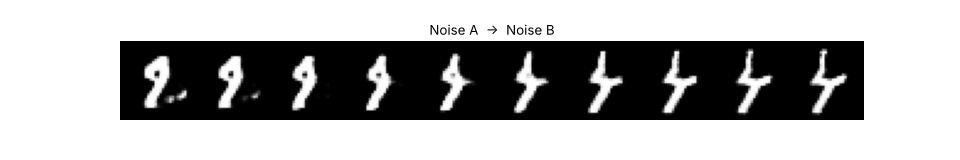

In [10]:
z1, z2 = torch.randn(1, Z_DIM, device=device), torch.randn(1, Z_DIM, device=device)
steps = torch.linspace(0, 1, 10, device=device).view(-1, 1)
with torch.no_grad():
    G.eval(); walk = G(z1 * (1 - steps) + z2 * steps).cpu(); G.train()
plt.figure(figsize=(12, 2)); plt.axis("off"); plt.title("Noise A  →  Noise B")
plt.imshow(vutils.make_grid(walk, nrow=10, normalize=True).permute(1, 2, 0)); plt.show()

## 10. Save the trained models

In [11]:
torch.save(G.state_dict(), "generator.pth")
torch.save(D.state_dict(), "discriminator.pth")
print("Saved generator.pth and discriminator.pth")

Saved generator.pth and discriminator.pth


## Conclusion
- With **no labels at all**, the Generator learned to draw readable handwritten digits just by trying to fool the Discriminator.
- The scores show the game working: `D(x)` (real) and `D(G(z))` (fake) settle between 0 and 1 instead of the Detective winning outright.
- The classifier check shows the fakes are readable and cover all ten digits — no mode collapse.

**References:** Goodfellow et al., *Generative Adversarial Nets*, NeurIPS 2014 · Radford, Metz & Chintala, *DCGAN*, ICLR 2016 · PyTorch DCGAN tutorial · Towards Data Science, *Intuitive Introduction to GANs*.